# Proyek Analisis Data: E-Commerce Public Dataset (Olist)
- **Nama:** [Isi nama Anda]
- **Email:** [Isi email Anda]
- **ID Dicoding:** [Isi ID Dicoding Anda]

## Menentukan Pertanyaan Bisnis
Konteks: Olist adalah marketplace Brasil yang menghubungkan penjual kecil dengan pelanggan. Periode analisis dibatasi **Januari 2017 – Agustus 2018** karena data 2016 sangat sedikit dan data September–Oktober 2018 tidak lengkap.

1. **Kategori produk apa yang menghasilkan total revenue (jumlah `price`, tanpa ongkir) tertinggi (Top 10) dan terendah (Bottom 5) pada pesanan berstatus *delivered* selama Januari 2017 – Agustus 2018, dan berapa kontribusi Top 10 terhadap total revenue?** → dasar penentuan prioritas stok, promosi, dan penjual.
2. **Di negara bagian (state) mana persentase pesanan terlambat (dikirim melewati estimasi) paling tinggi selama Januari 2017 – Agustus 2018, dan berapa selisih rata-rata review score antara pesanan terlambat dan tepat waktu?** → dasar penentuan wilayah prioritas perbaikan logistik.
3. **Bagaimana segmentasi pelanggan berdasarkan Recency, Frequency, dan Monetary (RFM) per akhir Agustus 2018, dan berapa persen pelanggan yang pernah repeat order?** → dasar strategi retensi dan *win-back*.

Setiap pertanyaan spesifik (satu topik jelas), terukur (revenue, persentase, skor), berorientasi aksi, relevan dengan tujuan bisnis (pertumbuhan dan kepuasan pelanggan), dan terikat periode waktu.

## Menyiapkan semua library yang dibutuhkan

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')
sns.set_theme(style='whitegrid')

## Data Wrangling

### Gathering Data
Tabel yang dipakai: orders, order_items, products, product_category_name_translation, customers, dan order_reviews.

In [2]:
orders_df = pd.read_csv('data/orders_dataset.csv')
items_df = pd.read_csv('data/order_items_dataset.csv')
products_df = pd.read_csv('data/products_dataset.csv')
translation_df = pd.read_csv('data/product_category_name_translation.csv')
customers_df = pd.read_csv('data/customers_dataset.csv')
reviews_df = pd.read_csv('data/order_reviews_dataset.csv')
for name, df in [('orders', orders_df), ('items', items_df), ('products', products_df),
                 ('translation', translation_df), ('customers', customers_df), ('reviews', reviews_df)]:
    print(f'{name:12s} {df.shape}')
orders_df.head()

orders       (99441, 8)
items        (112650, 7)
products     (32951, 9)
translation  (71, 2)
customers    (99441, 5)
reviews      (99224, 7)


,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date
0,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,delivered,2017-10-02 10:56:33,2017-10-02 11:07:15,2017-10-04 19:55:00,2017-10-10 21:25:13,2017-10-18 00:00:00
1,53cdb2fc8bc7dce0b6741e2150273451,b0830fb4747a6c6d20dea0b8c802d7ef,delivered,2018-07-24 20:41:37,2018-07-26 03:24:27,2018-07-26 14:31:00,2018-08-07 15:27:45,2018-08-13 00:00:00
2,47770eb9100c2d0c44946d9cf07ec65d,41ce2a54c0b03bf3443c3d931a367089,delivered,2018-08-08 08:38:49,2018-08-08 08:55:23,2018-08-08 13:50:00,2018-08-17 18:06:29,2018-09-04 00:00:00
3,949d5b44dbf5de918fe9c16f97b45f8a,f88197465ea7920adcdbec7375364d82,delivered,2017-11-18 19:28:06,2017-11-18 19:45:59,2017-11-22 13:39:59,2017-12-02 00:28:42,2017-12-15 00:00:00
4,ad21c59c0840e6cb83a9ceb5573f8159,8ab97904e6daea8866dbdbc4fb7aad2c,delivered,2018-02-13 21:18:39,2018-02-13 22:20:29,2018-02-14 19:46:34,2018-02-16 18:17:02,2018-02-26 00:00:00


**Insight:**
- Terdapat 6 tabel yang saling terhubung lewat `order_id`, `customer_id`, dan `product_id`.
- Tabel `orders` berisi sekitar 99 ribu pesanan, sehingga cukup besar untuk analisis tren dan segmentasi.

### Assessing Data

In [3]:
tables = {'orders': orders_df, 'items': items_df, 'products': products_df,
          'translation': translation_df, 'customers': customers_df, 'reviews': reviews_df}
summary = pd.DataFrame({
    'jumlah_baris': {k: len(v) for k, v in tables.items()},
    'total_missing': {k: int(v.isna().sum().sum()) for k, v in tables.items()},
    'duplikat_baris': {k: int(v.duplicated().sum()) for k, v in tables.items()},
})
summary

,jumlah_baris,total_missing,duplikat_baris
orders,99441,4908,0
items,112650,0,0
products,32951,2448,0
translation,71,0,0
customers,99441,0,0
reviews,99224,145903,0


In [4]:
print('Missing value orders:'); print(orders_df.isna().sum()[lambda s: s > 0], '\n')
print('Missing value products:'); print(products_df.isna().sum()[lambda s: s > 0], '\n')
print('Missing value reviews:'); print(reviews_df.isna().sum()[lambda s: s > 0])

Missing value orders:
order_approved_at                 160
order_delivered_carrier_date     1783
order_delivered_customer_date    2965
dtype: int64 

Missing value products:
product_category_name         610
product_name_lenght           610
product_description_lenght    610
product_photos_qty            610
product_weight_g                2
product_length_cm               2
product_height_cm               2
product_width_cm                2
dtype: int64 

Missing value reviews:
review_comment_title      87656
review_comment_message    58247
dtype: int64


In [5]:
# Invalid value: pesanan 'delivered' tetapi tanggal terima pelanggan kosong
delivered = orders_df[orders_df['order_status'] == 'delivered']
print('Delivered tanpa tanggal diterima:', delivered['order_delivered_customer_date'].isna().sum())

# Duplicate data: satu order memiliki lebih dari satu review
print('order_id ganda pada reviews:', reviews_df['order_id'].duplicated().sum())

# Inconsistent value: kategori Portugis vs Inggris, dan kategori tanpa terjemahan
prod_tr = products_df.merge(translation_df, on='product_category_name', how='left')
no_tr = prod_tr[prod_tr['product_category_name'].notna() & prod_tr['product_category_name_english'].isna()]
print('Kategori tanpa terjemahan:', no_tr['product_category_name'].unique())

# Outlier: lama pengiriman
tmp = delivered.dropna(subset=['order_delivered_customer_date']).copy()
tmp['days'] = (pd.to_datetime(tmp['order_delivered_customer_date']) - pd.to_datetime(tmp['order_purchase_timestamp'])).dt.days
print(tmp['days'].describe())

Delivered tanpa tanggal diterima: 8
order_id ganda pada reviews: 551
Kategori tanpa terjemahan: <ArrowStringArray>
['pc_gamer', 'portateis_cozinha_e_preparadores_de_alimentos']
Length: 2, dtype: str
count    96470.000000
mean        12.093604
std          9.551380
min          0.000000
25%          6.000000
50%         10.000000
75%         15.000000
max        209.000000
Name: days, dtype: float64


**Insight (masalah yang ditemukan dan rencana penanganan):**

| Masalah | Temuan | Tindakan di tahap Cleaning |
|---|---|---|
| Missing value | `product_category_name` kosong pada 610 produk; tanggal pengiriman/diterima kosong pada ribuan pesanan yang belum selesai | Isi kategori kosong dengan `unknown`; analisis dibatasi pada pesanan *delivered* |
| Invalid value | 8 pesanan *delivered* tidak memiliki tanggal diterima pelanggan | Hapus baris tersebut |
| Duplicate data | 551 `order_id` memiliki lebih dari satu review | Pertahankan review terbaru per pesanan |
| Inconsistent value | Nama kategori berbahasa Portugis; 2 kategori tidak ada terjemahannya | Gunakan terjemahan Inggris, sisanya pakai nama asli |
| Outlier | Lama pengiriman maksimum 209 hari (median 10 hari) | Dipertahankan karena nilai valid (kasus nyata), dilaporkan lewat median |
| Rentang waktu | Data 2016 sangat sedikit dan Sep–Okt 2018 tidak lengkap | Filter Jan 2017 – Agu 2018 |

### Cleaning Data

In [6]:
# 1. Duplicate: ambil review terbaru per order
reviews_df['review_answer_timestamp'] = pd.to_datetime(reviews_df['review_answer_timestamp'])
reviews_clean = (reviews_df.sort_values('review_answer_timestamp')
                 .drop_duplicates('order_id', keep='last')[['order_id', 'review_score']])
print('Review unik per order:', reviews_clean['order_id'].is_unique)

Review unik per order: True


In [7]:
# 2. Missing + inconsistent: kategori produk
products_clean = products_df.merge(translation_df, on='product_category_name', how='left')
products_clean['product_category'] = (products_clean['product_category_name_english']
                                      .fillna(products_clean['product_category_name'])
                                      .fillna('unknown'))
products_clean = products_clean[['product_id', 'product_category']]
products_clean['product_category'].isna().sum()

np.int64(0)

In [8]:
# 3. Invalid value + filter periode
date_cols = ['order_purchase_timestamp', 'order_delivered_customer_date', 'order_estimated_delivery_date']
for c in date_cols:
    orders_df[c] = pd.to_datetime(orders_df[c])

orders_clean = orders_df[orders_df['order_status'] == 'delivered'].dropna(subset=['order_delivered_customer_date'])
orders_clean = orders_clean[(orders_clean['order_purchase_timestamp'] >= '2017-01-01') &
                            (orders_clean['order_purchase_timestamp'] < '2018-09-01')]
orders_clean = orders_clean[['order_id', 'customer_id'] + date_cols].copy()
orders_clean['delivery_days'] = (orders_clean['order_delivered_customer_date'] - orders_clean['order_purchase_timestamp']).dt.days
orders_clean['is_late'] = orders_clean['order_delivered_customer_date'] > orders_clean['order_estimated_delivery_date']
print('Pesanan setelah cleaning:', len(orders_clean))

Pesanan setelah cleaning: 96203


In [9]:
# 4. Gabungkan seluruh tabel menjadi satu dataset utama (level item pesanan)
main_df = (orders_clean
           .merge(items_df[['order_id', 'product_id', 'price', 'freight_value']], on='order_id')
           .merge(products_clean, on='product_id', how='left')
           .merge(customers_df[['customer_id', 'customer_unique_id', 'customer_state', 'customer_city']], on='customer_id')
           .merge(reviews_clean, on='order_id', how='left'))
print(main_df.shape)
print('Missing review_score:', main_df['review_score'].isna().sum())
main_df.to_csv('dashboard/main_data.csv', index=False)
main_df.head()

(109872, 15)
Missing review_score: 823


,order_id,customer_id,order_purchase_timestamp,order_delivered_customer_date,order_estimated_delivery_date,delivery_days,is_late,product_id,price,freight_value,product_category,customer_unique_id,customer_state,customer_city,review_score
0,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,2017-10-02 10:56:33,2017-10-10 21:25:13,2017-10-18,8,False,87285b34884572647811a353c7ac498a,29.99,8.72,housewares,7c396fd4830fd04220f754e42b4e5bff,SP,sao paulo,4.0
1,53cdb2fc8bc7dce0b6741e2150273451,b0830fb4747a6c6d20dea0b8c802d7ef,2018-07-24 20:41:37,2018-08-07 15:27:45,2018-08-13,13,False,595fac2a385ac33a80bd5114aec74eb8,118.70,22.76,perfumery,af07308b275d755c9edb36a90c618231,BA,barreiras,4.0
2,47770eb9100c2d0c44946d9cf07ec65d,41ce2a54c0b03bf3443c3d931a367089,2018-08-08 08:38:49,2018-08-17 18:06:29,2018-09-04,9,False,aa4383b373c6aca5d8797843e5594415,159.90,19.22,auto,3a653a41f6f9fc3d2a113cf8398680e8,GO,vianopolis,5.0
3,949d5b44dbf5de918fe9c16f97b45f8a,f88197465ea7920adcdbec7375364d82,2017-11-18 19:28:06,2017-12-02 00:28:42,2017-12-15,13,False,d0b61bfb1de832b15ba9d266ca96e5b0,45.00,27.20,pet_shop,7c142cf63193a1473d2e66489a9ae977,RN,sao goncalo do amarante,5.0
4,ad21c59c0840e6cb83a9ceb5573f8159,8ab97904e6daea8866dbdbc4fb7aad2c,2018-02-13 21:18:39,2018-02-16 18:17:02,2018-02-26,2,False,65266b2da20d04dbe00c5c2d3bb7859e,19.90,8.72,stationery,72632f0f9dd73dfee390c9b22eb56dd6,SP,santo andre,5.0


**Insight:**
- Seluruh masalah pada tahap Assessing sudah ditangani. Dataset utama (`main_df`) berisi sekitar 110 ribu item dari 96.203 pesanan *delivered*.
- Sebagian kecil pesanan (sekitar 0,8% item) tidak memiliki review; baris tetap dipertahankan dan hanya dikeluarkan saat menghitung rata-rata skor.
- Dataset disimpan sebagai `dashboard/main_data.csv` agar dashboard tidak perlu menggabungkan tabel lagi.

## Exploratory Data Analysis (EDA)

### Eksplorasi Data Umum

In [10]:
order_df = main_df.drop_duplicates('order_id')
print('Jumlah pesanan      :', order_df['order_id'].nunique())
print('Jumlah pelanggan    :', main_df['customer_unique_id'].nunique())
print('Total revenue (BRL) :', round(main_df['price'].sum(), 2))
print('Jumlah kategori     :', main_df['product_category'].nunique())
main_df[['price', 'freight_value', 'delivery_days', 'review_score']].describe().round(2)

Jumlah pesanan      : 96203
Jumlah pelanggan    : 93096
Total revenue (BRL) : 13179777.95
Jumlah kategori     : 74


,price,freight_value,delivery_days,review_score
count,109872.00,109872.00,109872.00,109049.00
mean,119.96,19.95,11.99,4.08
std,182.35,15.70,9.43,1.35
min,0.85,0.00,0.00,1.00
25%,39.90,13.08,6.00,4.00
50%,74.90,16.26,10.00,5.00
75%,134.04,21.15,15.00,5.00
max,6735.00,409.68,209.00,5.00


### Pertanyaan 1: Kategori dengan revenue tertinggi dan terendah

In [11]:
cat_df = (main_df.groupby('product_category')
          .agg(revenue=('price', 'sum'), orders=('order_id', 'nunique'), avg_price=('price', 'mean'))
          .sort_values('revenue', ascending=False))
total_rev = cat_df['revenue'].sum()
cat_df['share_pct'] = cat_df['revenue'] / total_rev * 100
print('Top 10:'); display(cat_df.head(10).round(2))
print('Bottom 5:'); display(cat_df.tail(5).round(2))
print(f"Kontribusi Top 10 terhadap total revenue: {cat_df['share_pct'].head(10).sum():.1f}%")

Top 10:


,revenue,orders,avg_price,share_pct
product_category,,,,
health_beauty,1229557.50,8610,130.50,9.33
watches_gifts,1163187.91,5489,198.73,8.83
bed_bath_table,1022955.77,9267,93.46,7.76
sports_leisure,952661.40,7512,113.24,7.23
computers_accessories,887944.60,6517,116.36,6.74
furniture_decor,706237.17,6258,87.24,5.36
housewares,614341.62,5734,90.57,4.66
cool_stuff,609158.00,3552,164.15,4.62
auto,577721.09,3801,139.85,4.38


Bottom 5:


,revenue,orders,avg_price,share_pct
product_category,,,,
flowers,1110.04,29,33.64,0.01
home_comfort_2,760.27,24,25.34,0.01
cds_dvds_musicals,730.00,12,52.14,0.01
fashion_childrens_clothes,519.95,7,74.28,0.00
security_and_services,283.29,2,141.64,0.00


Kontribusi Top 10 terhadap total revenue: 62.5%


In [12]:
monthly_rev = main_df.groupby(main_df['order_purchase_timestamp'].dt.to_period('M'))['price'].sum()
print(monthly_rev.round(0).to_string())
print('Pertumbuhan Jan 2017 -> Agu 2018 (x):', round(monthly_rev.iloc[-1] / monthly_rev.iloc[0], 1))

order_purchase_timestamp
2017-01    111798.0
2017-02    234223.0
2017-03    359199.0
2017-04    340670.0
2017-05    489159.0
2017-06    421923.0
2017-07    481605.0
2017-08    554700.0
2017-09    607400.0
2017-10    648248.0
2017-11    987648.0
2017-12    726033.0
2018-01    924645.0
2018-02    826437.0
2018-03    953356.0
2018-04    973534.0
2018-05    977545.0
2018-06    855592.0
2018-07    867486.0
2018-08    838577.0
Freq: M
Pertumbuhan Jan 2017 -> Agu 2018 (x): 7.5


### Pertanyaan 2: Keterlambatan pengiriman per state dan dampaknya ke review

In [13]:
state_df = (order_df.groupby('customer_state')
            .agg(orders=('order_id', 'count'), late_pct=('is_late', 'mean'),
                 avg_review=('review_score', 'mean'), avg_delivery_days=('delivery_days', 'mean')))
state_df['late_pct'] *= 100
state_big = state_df[state_df['orders'] >= 300].sort_values('late_pct', ascending=False)  # state dengan sampel memadai
display(state_big.round(2).head(8))
print('Pesanan terlambat nasional (%):', round(order_df['is_late'].mean() * 100, 2))

,orders,late_pct,avg_review,avg_delivery_days
customer_state,,,,
AL,396,23.99,3.85,24.02
MA,713,19.64,3.83,21.08
PI,475,16.00,3.99,18.98
CE,1273,15.40,3.94,20.79
SE,332,15.36,3.90,20.95
BA,3253,14.05,3.93,18.87
RJ,12310,13.52,3.97,14.84
PA,942,12.42,3.91,23.30


Pesanan terlambat nasional (%): 8.13


In [14]:
review_late = order_df.groupby('is_late')['review_score'].agg(['mean', 'count']).round(2)
review_late.index = ['Tepat waktu', 'Terlambat']
display(review_late)
print('Selisih rata-rata skor:', round(review_late.loc['Tepat waktu', 'mean'] - review_late.loc['Terlambat', 'mean'], 2))
print('Median hari pengiriman SP vs AL:',
      order_df[order_df.customer_state=='SP']['delivery_days'].median(), 'vs',
      order_df[order_df.customer_state=='AL']['delivery_days'].median())

,mean,count
Tepat waktu,4.29,87902
Terlambat,2.57,7658


Selisih rata-rata skor: 1.72
Median hari pengiriman SP vs AL: 7.0 vs 22.0


**Insight EDA:**
- Revenue sangat terkonsentrasi pada beberapa kategori: `health_beauty`, `watches_gifts`, dan `bed_bath_table` menempati tiga teratas (masing-masing sekitar Rp/BRL 1,0–1,2 juta). Sepuluh kategori teratas menyumbang sekitar 62,5% total revenue.
- Kategori terendah (mis. `security_and_services`, `fashion_childrens_clothes`, `cds_dvds_musicals`) hanya menghasilkan ratusan BRL dengan kurang dari 15 pesanan.
- Revenue bulanan tumbuh sekitar 7,5x dari Jan 2017 ke Agu 2018, dengan puncak musiman pada Nov 2017 (periode Black Friday).
- Pesanan terlambat nasional sekitar 8,1%, namun state di wilayah Utara dan Timur Laut (AL, MA, PI, CE, SE) mencapai 15–24%, sedangkan SP, MG, dan PR hanya sekitar 5–6%.
- Pesanan terlambat mendapat skor rata-rata sekitar 2,57 versus 4,29 untuk pesanan tepat waktu (selisih sekitar 1,7 poin).

## Visualization & Explanatory Analysis

### Pertanyaan 1: Kategori dengan revenue tertinggi dan terendah

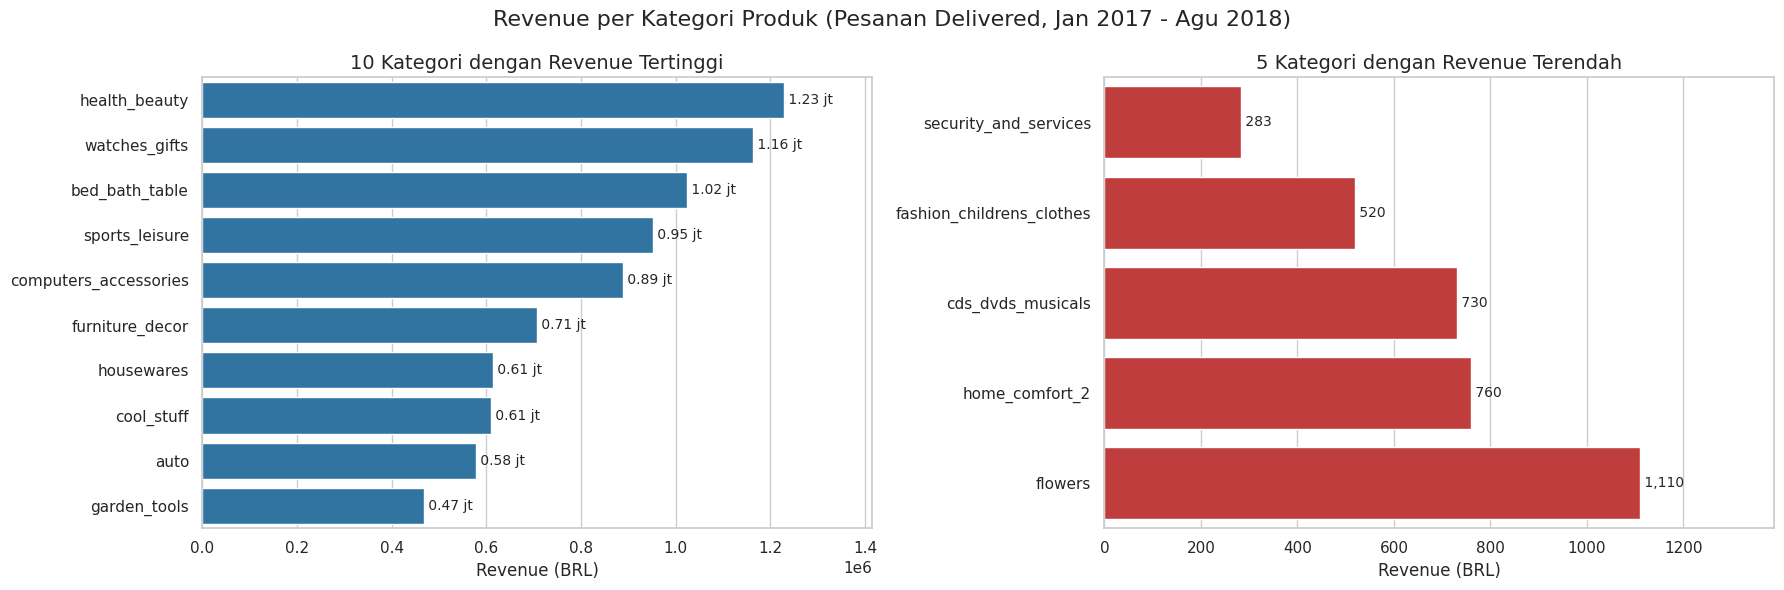

In [15]:
top10 = cat_df.head(10).reset_index()
bottom5 = cat_df.tail(5).reset_index().sort_values('revenue')

fig, ax = plt.subplots(1, 2, figsize=(18, 6))
sns.barplot(data=top10, y='product_category', x='revenue', ax=ax[0], color='#1f77b4')
ax[0].set_title('10 Kategori dengan Revenue Tertinggi', fontsize=14)
ax[0].set_xlabel('Revenue (BRL)'); ax[0].set_ylabel('')
for i, v in enumerate(top10['revenue']):
    ax[0].text(v, i, f' {v/1e6:.2f} jt', va='center', fontsize=10)
ax[0].set_xlim(0, top10['revenue'].max() * 1.15)

sns.barplot(data=bottom5, y='product_category', x='revenue', ax=ax[1], color='#d62728')
ax[1].set_title('5 Kategori dengan Revenue Terendah', fontsize=14)
ax[1].set_xlabel('Revenue (BRL)'); ax[1].set_ylabel('')
for i, v in enumerate(bottom5['revenue']):
    ax[1].text(v, i, f' {v:,.0f}', va='center', fontsize=10)
ax[1].set_xlim(0, bottom5['revenue'].max() * 1.25)
plt.suptitle('Revenue per Kategori Produk (Pesanan Delivered, Jan 2017 - Agu 2018)', fontsize=16)
plt.tight_layout(); plt.show()

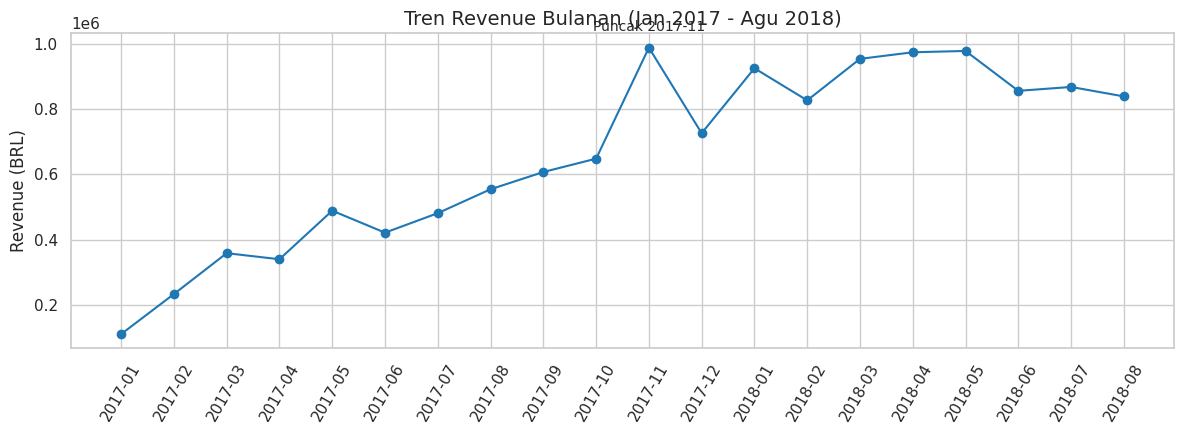

In [16]:
fig, ax = plt.subplots(figsize=(12, 4.5))
ax.plot(monthly_rev.index.astype(str), monthly_rev.values, marker='o', color='#1f77b4')
ax.set_title('Tren Revenue Bulanan (Jan 2017 - Agu 2018)', fontsize=14)
ax.set_ylabel('Revenue (BRL)'); ax.tick_params(axis='x', rotation=60)
peak = monthly_rev.idxmax(); ax.annotate(f'Puncak {peak}', (str(peak), monthly_rev.max()), xytext=(0, 12),
                                         textcoords='offset points', ha='center', fontsize=10)
plt.tight_layout(); plt.show()

**Insight:** Revenue didominasi kategori kebutuhan rumah tangga, kecantikan, dan hadiah. Kategori bawah hampir tidak berkontribusi. Tren bulanan menunjukkan pertumbuhan yang kuat dengan lonjakan di November 2017.

### Pertanyaan 2: Keterlambatan pengiriman per state dan dampaknya pada review

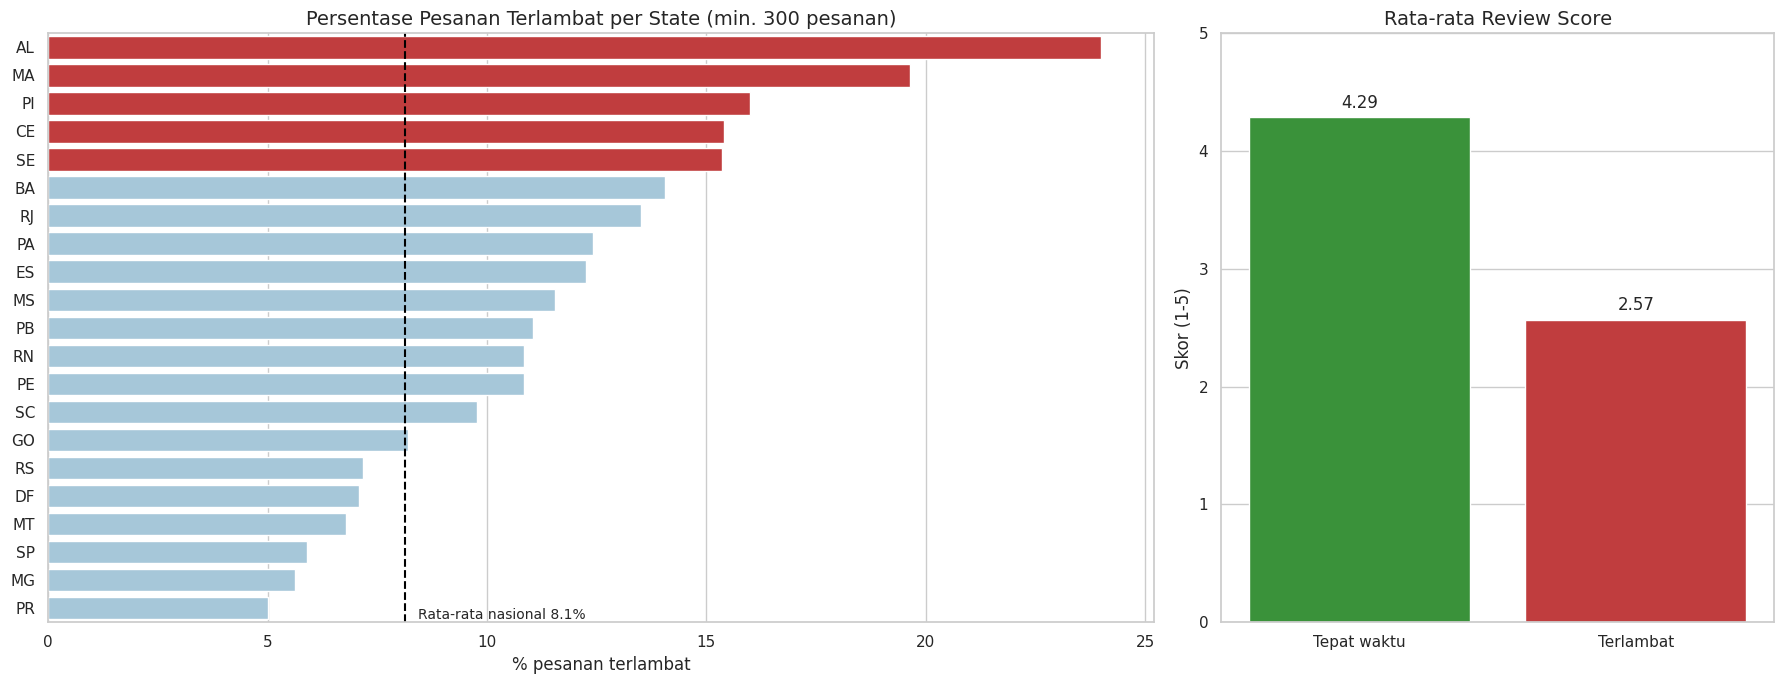

In [17]:
plot_state = state_big.reset_index()
nat = order_df['is_late'].mean() * 100
colors = ['#d62728' if v > 15 else '#9ecae1' for v in plot_state['late_pct']]

fig, ax = plt.subplots(1, 2, figsize=(18, 7), gridspec_kw={'width_ratios': [2, 1]})
sns.barplot(data=plot_state, y='customer_state', x='late_pct', palette=colors, hue='customer_state', legend=False, ax=ax[0])
ax[0].axvline(nat, color='black', linestyle='--'); ax[0].text(nat + 0.3, len(plot_state) - 0.6, f'Rata-rata nasional {nat:.1f}%', fontsize=10)
ax[0].set_title('Persentase Pesanan Terlambat per State (min. 300 pesanan)', fontsize=14)
ax[0].set_xlabel('% pesanan terlambat'); ax[0].set_ylabel('')

sns.barplot(data=review_late.reset_index(), x='index', y='mean', hue='index', palette=['#2ca02c', '#d62728'], legend=False, ax=ax[1])
ax[1].set_title('Rata-rata Review Score', fontsize=14); ax[1].set_xlabel(''); ax[1].set_ylabel('Skor (1-5)'); ax[1].set_ylim(0, 5)
for i, v in enumerate(review_late['mean']):
    ax[1].text(i, v + 0.08, f'{v:.2f}', ha='center', fontsize=12)
plt.tight_layout(); plt.show()

**Insight:** Keterlambatan terkonsentrasi di state Utara/Timur Laut (merah, di atas 15%). Dampaknya langsung terlihat pada kepuasan: pesanan terlambat mendapat skor rata-rata jauh lebih rendah dibanding pesanan tepat waktu.

## Analisis Lanjutan: RFM Analysis

RFM mengelompokkan pelanggan berdasarkan **Recency** (hari sejak pembelian terakhir), **Frequency** (jumlah pesanan), dan **Monetary** (total belanja). Karena sekitar 97% pelanggan hanya membeli satu kali, Frequency dipisah secara manual (*manual grouping*): pelanggan dengan ≥2 pesanan disebut **Repeat Buyer**. Pelanggan sekali beli di-*binning* memakai median Recency dan Monetary (teknik binning, tanpa machine learning). Tanggal referensi: 1 September 2018.

In [18]:
ref_date = main_df['order_purchase_timestamp'].max() + pd.Timedelta(days=1)
rfm = (main_df.groupby('customer_unique_id')
       .agg(last_order=('order_purchase_timestamp', 'max'), frequency=('order_id', 'nunique'), monetary=('price', 'sum'))
       .reset_index())
rfm['recency'] = (ref_date - rfm['last_order']).dt.days
rfm.drop(columns='last_order', inplace=True)

med_r, med_m = rfm['recency'].median(), rfm['monetary'].median()
def segment(r):
    if r['frequency'] >= 2: return 'Repeat Buyer'
    if r['recency'] <= med_r: return 'Recent High Spender' if r['monetary'] > med_m else 'Recent Low Spender'
    return 'Lapsed High Spender' if r['monetary'] > med_m else 'Lapsed Low Spender'
rfm['segment'] = rfm.apply(segment, axis=1)

print(f'Median recency: {med_r:.0f} hari | median monetary: {med_m:.1f} BRL')
print(f"Pelanggan repeat order: {(rfm['frequency'] >= 2).mean() * 100:.2f}%")
seg = (rfm.groupby('segment').agg(customers=('customer_unique_id', 'count'), avg_recency=('recency', 'mean'),
                                  avg_monetary=('monetary', 'mean'), total_monetary=('monetary', 'sum'))
       .sort_values('customers', ascending=False))
seg['customer_pct'] = seg['customers'] / seg['customers'].sum() * 100
seg['revenue_pct'] = seg['total_monetary'] / seg['total_monetary'].sum() * 100
seg.round(1)

Median recency: 218 hari | median monetary: 89.7 BRL
Pelanggan repeat order: 3.00%


,customers,avg_recency,avg_monetary,total_monetary,customer_pct,revenue_pct
segment,,,,,,
Lapsed Low Spender,23318,362.0,47.2,1101038.2,25.0,8.4
Recent Low Spender,22780,111.2,47.0,1070841.5,24.5,8.1
Recent High Spender,22244,111.8,231.6,5151070.8,23.9,39.1
Lapsed High Spender,21965,362.5,233.6,5131472.4,23.6,38.9
Repeat Buyer,2789,219.6,260.1,725355.0,3.0,5.5


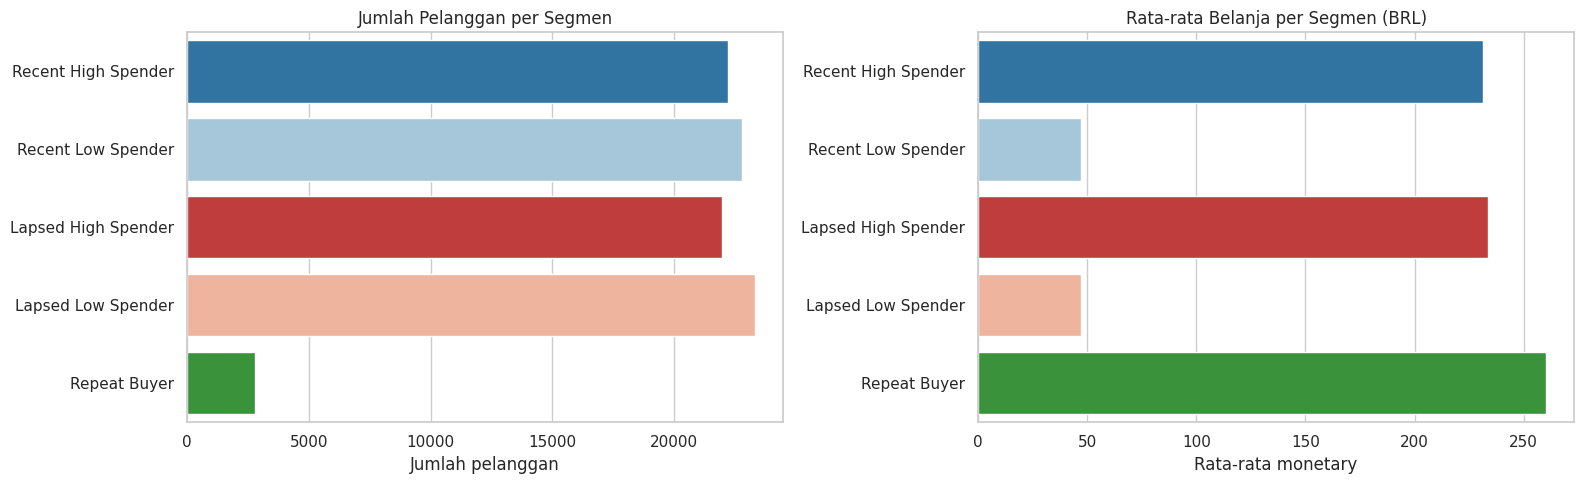

In [19]:
order_seg = ['Recent High Spender', 'Recent Low Spender', 'Lapsed High Spender', 'Lapsed Low Spender', 'Repeat Buyer']
seg_plot = seg.reindex(order_seg).reset_index()
pal = ['#1f77b4', '#9ecae1', '#d62728', '#fcae91', '#2ca02c']

fig, ax = plt.subplots(1, 2, figsize=(16, 5))
sns.barplot(data=seg_plot, x='customers', y='segment', hue='segment', palette=pal, legend=False, ax=ax[0])
ax[0].set_title('Jumlah Pelanggan per Segmen'); ax[0].set_xlabel('Jumlah pelanggan'); ax[0].set_ylabel('')
sns.barplot(data=seg_plot, x='avg_monetary', y='segment', hue='segment', palette=pal, legend=False, ax=ax[1])
ax[1].set_title('Rata-rata Belanja per Segmen (BRL)'); ax[1].set_xlabel('Rata-rata monetary'); ax[1].set_ylabel('')
plt.tight_layout(); plt.show()

**Insight RFM:**
- Hanya 3,0% pelanggan (±2.800 orang) yang pernah repeat order; sisanya pembeli satu kali.
- Dua segmen bernilai tinggi (*Recent* dan *Lapsed High Spender*) masing-masing hanya ±24% dari pelanggan tetapi menyumbang ±39% revenue, atau total ±78%. Rata-rata belanjanya ±232 BRL, sekitar lima kali segmen low spender (±47 BRL).
- *Lapsed High Spender* (pelanggan bernilai tinggi yang sudah lama tidak kembali) adalah target *win-back* paling bernilai karena belanja rata-ratanya besar.
- *Recent High Spender* adalah peluang terbaik untuk dikonversi menjadi pelanggan berulang dengan penawaran lanjutan.

## Conclusion

**Kesimpulan Pertanyaan 1 (kategori):**
`health_beauty`, `watches_gifts`, dan `bed_bath_table` adalah tiga kategori dengan revenue tertinggi (sekitar 1,0–1,2 juta BRL masing-masing), dan 10 kategori teratas menyumbang sekitar 62,5% dari total revenue 13,2 juta BRL. Lima kategori terendah (mis. `security_and_services`, `fashion_childrens_clothes`) hanya menghasilkan di bawah 1.200 BRL dengan kurang dari 30 pesanan. Revenue bulanan juga tumbuh sekitar 7,5x sepanjang periode, dengan puncak pada November 2017.

**Kesimpulan Pertanyaan 2 (keterlambatan):**
Rata-rata nasional pesanan terlambat sekitar 8,1%, tetapi AL (±24%), MA (±20%), PI, CE, dan SE (±15–16%) jauh di atasnya, sementara SP, MG, dan PR hanya sekitar 5–6%. Pesanan terlambat mendapat skor review rata-rata sekitar 2,57 dibanding 4,29 untuk pesanan tepat waktu, selisih sekitar 1,7 poin.

**Kesimpulan Pertanyaan 3 (RFM):**
Sekitar 97% pelanggan hanya membeli satu kali sehingga retensi menjadi peluang pertumbuhan terbesar. Segmen *Lapsed High Spender* (±22 ribu pelanggan, ±39% revenue) dan *Recent High Spender* (±22 ribu pelanggan, ±39% revenue) adalah dua kelompok yang paling layak diprioritaskan.

**Rekomendasi (Action Item):**
1. **Prioritaskan stok, iklan, dan insentif penjual pada 10 kategori teratas** (terutama `health_beauty`, `watches_gifts`, `bed_bath_table`), dan siapkan kampanye serta persediaan ekstra menjelang November (Black Friday). Evaluasi atau kurasi kategori bawah yang hampir tidak menghasilkan revenue.
2. **Perbaiki logistik di state prioritas (AL, MA, PI, CE, SE)**: tambahkan estimasi pengiriman yang lebih realistis di halaman checkout, negosiasikan SLA dengan mitra kurir, dan pertimbangkan penjual/gudang yang lebih dekat. Target awal: menurunkan keterlambatan di state tersebut ke bawah 10%.
3. **Jalankan program retensi berbasis RFM**: kirim kupon *win-back* ke *Lapsed High Spender* dan penawaran pembelian kedua (cross-sell kategori populer) ke *Recent High Spender*, dengan target menaikkan persentase repeat order dari ±3%.